# Step 7 — build the person-level feature table, 2005–2018

Follows `docs/skip_pattern_plan.txt`.

```
Population: age >= 20, not pregnant, PHQ-9 items all answered 0-3 (nhanes.cohort.population).
Starting set: features present in all 7 cycles (feature_catalog.csv in_all_0518), renamed pairs
merged (rename_map.csv). Long-format RXQ_RX enters only as rx_count (nhanes.harmonize.rx_counts); items
left in pending_features.txt are harmonised in nhanes/harmonize.py.

Encoding of every output feature:
  value / logically certain 0 : answered, or the answer follows from a gate question
  -1                          : not applicable, the questionnaire never asks this age / sex
  NaN                         : truly missing (eligible but blank, refused, don't know)
Refused / don't know codes come from the CDC codebooks (codebook_values.csv): every value whose
description is "Refused", "Don't know" or "Don't know/not sure" becomes NaN.

Then (decided 10/28): day-1 / day-2 dietary recalls are combined (mean of both days, day 1 alone
when there is no day 2; categorical items day 1 only), subsample-only labs (GLU, TRIGLY, PFAS)
leave the main table, and a feature is dropped when its missing rate is above 20% in any one cycle.

Output (features/):
  features_2005_2018.csv.gz  SEQN, cycle, design + weight columns, PHQ9 / depression (targets),
                             then the kept features
  subsample_labs_2005_2018.csv.gz  SEQN, cycle and the subsample-only labs
  feature_dictionary.csv     one row per feature: kind, source variables, encoding, type,
                             overall and per-cycle missing rate, status (kept / subsample_lab /
                             over_threshold)
  build_report.txt           sizes, kinds, checks of the age / sex rules per cycle
```

In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import io as nio  # noqa: E402
from nhanes.cohort import CYCLES, SHORT, population  # noqa: E402
from nhanes.harmonize import EXTRA_LOAD, calibrate_labs, harmonized, pfoa_pfos, rx_counts  # noqa: E402
from nhanes.paths import DRUG_FILE, WORK  # noqa: E402

## Rules: dropped, restricted and checkbox items

In [2]:
OUT = WORK / "features"
ALT = {"PFAS": ["PFAS", "PFC"], "COT": ["COT", "COTNAL"]}
NOT_ANSWER = {"refused", "don't know", "don't know/not sure", "dont know"}
KEEP_COLS = ["SDMVPSU", "SDMVSTRA", "WTINT2YR", "WTMEC2YR"]
MAX_MISSING = 0.20  # a feature is dropped when any one cycle misses more than this
SUBSAMPLE_LABS = {"GLU", "TRIGLY", "PFAS"}  # measured on a random subsample only; kept in a side file
EXTRA = {"DEMO": ["DMDBORN", "DMDBORN2", "DMDBORN4"] + KEEP_COLS}  # needed but not features
for _m, _v in EXTRA_LOAD.items():
    EXTRA[_m] = EXTRA.get(_m, []) + _v

# --- features replaced by a derived column or not used (skip_pattern_plan.txt sections 2-5) ---
DROP = {
    "SMQ": r"SMD030|SMD057|SMD093|SMD100.*|SMDUPCA|SMD641|SMD650|SMQ020|SMQ040|SMQ050[QU]|SMQ670",
    "BPQ": r"BPQ0[2-9]0.*|BPQ100D",
    "DIQ": r"DID.*|DIQ0[1-9]0|DIQ060U|DIQ2[3-6]0U?|DIQ3[5-6]0U?",
    "MCQ": r"MCD180.|MCD093|MCQ0[2-5][05]|MCQ170[KLM]|MCQ230.",
    "PFQ": r"PFQ059|PFQ061.|PFQ063.",  # PFQ059 pools mental limits and is covered by PFQ049-057
    "OCQ": r"OCD270|OCD395|OCQ180|OCQ210|OCQ260|OCQ380",
    "KIQ_U": r"KIQ010|KIQ025|KIQ05[02]|KIQ4[3-7]0",
    "RHQ": r"RHD143|RHD1[89]0|RHQ020|RHQ0[67]0|RHQ16[69]|RHQ171|RHQ200|RHQ291|RHQ5[5-9]\w*|RHQ60\w*",
    "DUQ": r"DUQ(?!200$|240$|370$)\w+",
    "CDQ": r"CDQ00[2-9]\w*",
    "WHQ": r"WHD080[QRS]|WHQ060",
    "HIQ": r"HIQ260",
    "DBQ": r"DBQ235.",
    "HUQ": r"HUD080",
    "HSQ": r"HSQ580",
    "ALQ": r"ALQ130",  # gate (ALQ101/110 vs ALQ111) still pending
    "SMQRTU": r".*",   # gate (SMQ680 vs SMQ681) still pending
    "DEMO": r"RIDAGEMN|RIDEXPRG|DMDYRSUS",
    "BPX": r"BPX[SD][YI]4",
    "DR1TOT": r"DRD3[57]0\w+",
}
# --- age / sex restricted questions: -1 outside the ages / sex that are asked ---
RESTRICT = {  # variable: (min_age, max_age, sex or None)
    "DUQ200": (20, 59, None), "DUQ240": (20, 59, None), "DUQ370": (20, 59, None),
    "CDQ001": (40, 200, None), "CDQ010": (40, 200, None),
    "WHD110": (36, 200, None), "WHD130": (50, 200, None),
    "DBQ301": (60, 200, None), "DBQ330": (60, 200, None),
    **{v: (20, 200, 2) for v in ["RHQ010", "RHQ031", "RHQ131", "RHD280", "RHQ420", "RHQ540"]},
}
# --- checkbox items: 1 chosen, 0 asked but not chosen or gate answered no ---
CHECKBOX = {  # prefix pattern: (asked(df) -> bool Series, gate_no(df) -> bool Series)
    r"WHD080[A-P]": (lambda d: d.WHQ070.eq(1) | d.WHQ060.eq(1), lambda d: d.WHQ070.eq(2) & ~d.WHQ060.eq(1)),
    r"HIQ031(A|B|C|D|E|F|H|I|J)": (lambda d: d.HIQ011.eq(1), lambda d: d.HIQ011.eq(2)),
    r"DBQ223[A-D]": (lambda d: d.DBQ197.isin([1, 2, 3, 4]), lambda d: d.DBQ197.eq(0)),
    r"RHQ542[A-C]": (lambda d: d.RHQ540.eq(1), lambda d: d.RHQ540.eq(2)),
    r"DRQSDT(\d|91)": (lambda d: d.DRQSDIET.eq(1), lambda d: d.DRQSDIET.eq(2)),
}


def special_codes():
    v = pd.read_csv(WORK / "codebook_values.csv", dtype=str).fillna("")
    v = v[v.description.str.lower().str.strip().isin(NOT_ANSWER)]
    v = v[v.code.str.fullmatch(r"\d+")]
    rmap = pd.read_csv(WORK / "rename_map.csv")
    codes = v.groupby("variable").code.agg(lambda s: {float(c) for c in s}).to_dict()
    for r in rmap.itertuples():  # a renamed pair shares its codes
        codes[r.new] = codes.get(r.new, set()) | codes.get(r.old, set())
    ranged = set(pd.read_csv(WORK / "codebook_values.csv", dtype=str).dropna()
                 .query("code.str.contains(' to ')", engine="python").variable)
    return codes, ranged


def clean(s, codes):
    s = pd.to_numeric(s, errors="coerce")
    s = s.where(~np.isclose(s.fillna(1), 0) | (s == 0), 0.0)  # SAS writes 0 as 5.4e-79
    return s.where(~s.isin(codes)) if codes else s


def load(features, codes):
    rmap = pd.read_csv(WORK / "rename_map.csv")
    frames = []
    for cycle in CYCLES:
        df = population(cycle)[["SEQN", "RIDAGEYR", "RIAGENDR"]]
        wanted = {m: set(v) for m, v in features.groupby("module").variable}
        for m, v in EXTRA.items():
            wanted[m] = wanted.get(m, set()) | set(v)
        for module, want in wanted.items():
            d = nio.read_component(ALT.get(module, module), cycle, required=False)
            if d is None:
                continue
            d = d.rename(columns={r.old: r.new for r in rmap[rmap.module == module].itertuples()})
            take = [c for c in d.columns if c in want and c not in df.columns]
            df = df.merge(d[["SEQN"] + take], on="SEQN", how="left")
        dpq = nio.read_component("DPQ", cycle, nio.PHQ_ITEMS)
        df = df.merge(dpq, on="SEQN", how="left")
        df.insert(1, "cycle", SHORT[cycle])
        frames.append(df)
    df = pd.concat(frames, ignore_index=True, sort=False)
    for c in df.columns:
        if c not in ("SEQN", "cycle") and c not in KEEP_COLS:
            df[c] = clean(df[c], codes.get(c, set()))
    return df


def yes(s):
    """1/2 yes-no item -> 1/0, anything else NaN."""
    return s.map({1: 1.0, 2: 0.0})


def derive(d):
    """The derived columns of skip_pattern_plan.txt section 2, as {name: (series, sources, rule)}."""
    out = {}
    never, current = d.SMQ020.eq(2), d.SMQ040.isin([1, 2])
    status = np.select([never, d.SMQ040.eq(3), current], [0, 1, 2], np.nan)
    out["smoking_status"] = (status, "SMQ020, SMQ040", "0 never (<100 cigs) / 1 former / 2 current")
    out["cigs_per_day"] = (np.where(current, d.SMD650, np.where(never | d.SMQ040.eq(3), 0, np.nan)),
                           "SMQ020, SMQ040, SMD650", "current smokers: SMD650; others 0")

    out["htn_dx"] = (yes(d.BPQ020), "BPQ020", "doctor ever said high blood pressure")
    htn_no = d.BPQ020.eq(2) | d.BPQ040A.eq(2) | d.BPQ050A.eq(2)
    out["htn_med"] = (np.where(d.BPQ050A.eq(1), 1, np.where(htn_no, 0, np.nan)),
                      "BPQ020, BPQ040A, BPQ050A", "now taking prescribed BP medicine; no diagnosis / not told -> 0")

    checked = d.BPQ060.eq(1) | d.BPQ080.eq(1)
    never_checked = d.BPQ060.eq(2) & ~d.BPQ080.eq(1)
    out["chol_checked"] = (np.where(checked, 1, np.where(never_checked, 0, np.nan)), "BPQ060, BPQ080",
                           "ever had cholesterol checked (2011+ asks BPQ080 first)")
    dx = np.where(d.BPQ080.eq(1), 1, np.where(d.BPQ080.eq(2) | never_checked, 0, np.nan))
    out["chol_dx"] = (dx, "BPQ060, BPQ080", "told cholesterol high; never checked -> 0 (2005-10 skips BPQ080)")
    med = np.where((dx == 1) & d.BPQ090D.eq(1) & d.BPQ100D.eq(1), 1,
                   np.where((dx == 0) | ((dx == 1) & (d.BPQ090D.eq(2) | d.BPQ100D.eq(2))), 0, np.nan))
    out["chol_med"] = (med, "BPQ080, BPQ090D, BPQ100D",
                       "told high AND told to take medicine AND now taking; else 0 (2011+ non-high forced to 0)")
    last = np.where(never_checked, 5, d.BPQ070)
    out["chol_last_checked"] = (last, "BPQ060, BPQ070, BPQ080", "1 <1y / 2 1-2y / 3 2-5y / 4 5y+ / 5 never")

    out["diabetes_status"] = (d.DIQ010.map({2: 0.0, 3: 1.0, 1: 2.0}), "DIQ010", "0 no / 1 borderline / 2 yes")
    out["insulin"] = (yes(d.DIQ050), "DIQ050", "taking insulin now (asked of everyone)")
    oral_asked = d.DIQ010.isin([1, 3]) | d.DIQ160.eq(1)
    oral_no = d.DIQ010.eq(2) & ~d.DIQ160.eq(1)
    out["diabetes_pills"] = (np.where(oral_asked, yes(d.DIQ070), np.where(oral_no, 0, np.nan)),
                             "DIQ010, DIQ160, DIQ070", "asked if diabetes / borderline / prediabetes; others 0")

    for name, gate, follow in [("asthma_current", "MCQ010", "MCQ035"), ("thyroid_current", "MCQ160M", "MCQ170M"),
                               ("bronchitis_current", "MCQ160K", "MCQ170K"), ("liver_current", "MCQ160L", "MCQ170L")]:
        out[name] = (np.where(d[gate].eq(2), 0, np.where(d[gate].eq(1), yes(d[follow]), np.nan)),
                     f"{gate}, {follow}", f"ever had AND still has; {gate} no -> 0")

    items = [f"PFQ061{x}" for x in "ABCDEFGHIJKLMNOPQRST"]
    pf = d[items].copy()
    pf.loc[d.PFQ054.eq(1), ["PFQ061B", "PFQ061C"]] = 4  # not shown to equipment users: unable without it
    asked = pf.notna().any(axis=1)
    no_limit = (d.RIDAGEYR < 60) & d.PFQ049.eq(2) & d.PFQ057.eq(2) & d.PFQ059.eq(2) & ~asked
    pf.loc[no_limit, items] = 1
    answered = pf.notna().any(axis=1)
    out["pf_difficulty_count"] = (pf.isin([2, 3, 4]).sum(axis=1).where(answered), "PFQ049-059, PFQ061A-T",
                                  "# of 20 activities with some / much difficulty or unable; <60 without limits -> 0")
    out["pf_severe_count"] = (pf.isin([3, 4]).sum(axis=1).where(answered), "PFQ061A-T", "# with much difficulty or unable")
    out["pf_notdo_count"] = (pf.eq(5).sum(axis=1).where(answered), "PFQ061A-T", "# answered 'do not do this activity'")

    work = d.OCD150.eq(1)
    out["hours_worked"] = (np.where(work, d.OCQ180, np.where(d.OCD150.isin([2, 3, 4]), 0, np.nan)),
                           "OCD150, OCQ180", "worked last week: hours; others 0")
    out["not_working_reason"] = (np.where(d.OCD150.eq(4), d.OCQ380, np.where(d.OCD150.isin([1, 2]), 0,
                                          np.where(d.OCD150.eq(3), 10, np.nan))),
                                 "OCD150, OCQ380", "0 has a job / 10 looking for work / OCQ380 reason if not working")
    out["urine_leak_amount"] = (np.where(d.KIQ005.eq(1), 0, d.KIQ010), "KIQ005, KIQ010", "never leaks -> 0")

    born_us = pd.concat([d[c].eq(1).where(d[c].notna()) for c in ["DMDBORN", "DMDBORN2", "DMDBORN4"]],
                        axis=1).bfill(axis=1).iloc[:, 0]
    out["born_us"] = (born_us.astype(float), "DMDBORN / DMDBORN2 / DMDBORN4", "1 born in 50 states or DC (code 1 in all versions)")
    out["years_in_us"] = (np.where(born_us.eq(1.0), 0, d.DMDYRSUS), "DMDBORN*, DMDYRSUS",
                          "0 US-born; else DMDYRSUS category")

    for name, gate, prefix in [("shellfish_times", "DRD340", "DRD350"), ("fish_times", "DRD360", "DRD370")]:
        eaten = [c for c in d.columns if re.fullmatch(prefix + r"[A-U]", c)]
        total = sum(np.where(d[c].eq(1), d[f"{c}Q"], np.where(d[c].eq(2) | d[c].isna() & d[gate].eq(1), 0, np.nan))
                    if f"{c}Q" in d else 0 for c in eaten)  # item: 1 yes (then # times) / 2 no
        out[name] = (np.where(d[gate].eq(2), 0, np.where(d[gate].eq(1), total, np.nan)),
                     f"{gate}, {prefix}*, {prefix}*Q", "times eaten in past 30 days; none -> 0")

    # 2005-06 only: women with regular periods (RHQ031 = 1) were not asked about hysterectomy
    skipped = d.cycle.eq("2005-06") & d.RHQ031.eq(1) & d.RHD280.isna()
    out["RHD280"] = (np.where(d.RIAGENDR.eq(1), -1, np.where(skipped, 0, yes(d.RHD280))), "RHQ031, RHD280",
                     "hysterectomy; 2005-06 regular periods not asked -> 0; men -1")
    out["DBD100"] = (np.where(d.DBQ095Z.eq(4) & d.DBD100.isna(), 0, d.DBD100), "DBQ095Z, DBD100",
                     "how often add salt at table: 1 rarely / 2 occasionally / 3 very often; no salt at table -> 0")
    uninsured = d.HIQ011.eq(2)
    out["HIQ270"] = (np.where(uninsured & d.HIQ270.isna(), 0, yes(d.HIQ270)), "HIQ011, HIQ270",
                     "plan covers prescriptions; uninsured -> 0")
    out["HIQ210"] = (np.where(uninsured & d.HIQ210.isna(), 1, yes(d.HIQ210)), "HIQ011, HIQ210",
                     "time without insurance in past year; uninsured now -> 1")
    out["RHQ160"] = (np.where(d.RIAGENDR.eq(1), -1, np.where(d.RHQ131.eq(2), 0, d.RHQ160)),
                     "RHQ131, RHQ160", "# pregnancies; never pregnant -> 0; men -1")
    has = lambda c: d[c].notna()  # noqa: E731
    ins = np.select([d.HIQ011.eq(2), has("HIQ031A"), has("HIQ031B") | has("HIQ031C"),
                     has("HIQ031D") | has("HIQ031E") | has("HIQ031F") | has("HIQ031H") | has("HIQ031I"),
                     d.HIQ011.eq(1)], [0, 1, 2, 3, 4], np.nan)
    out["insurance_type"] = (ins, "HIQ011, HIQ031*", "0 none / 1 private / 2 Medicare (Medi-Gap) / 3 Medicaid or other public / 4 other")
    return out


DIET_DAY1_ONLY = {"_300", "LANG"}  # categorical day items: compare-to-usual, language


def combine_diet_days(out, rows):
    """Day-1 / day-2 recall pairs (decided 10/28): amounts become the mean of both days, or day 1
    alone when there is no day 2; categorical items keep day 1. Renames DR1x -> DR_x."""
    for c1 in [c for c in out.columns if c.startswith("DR1")]:
        c2 = "DR2" + c1[3:]
        if c2 not in out:
            continue
        name = "DR_" + c1[3:].lstrip("_")
        row = next(x for x in rows if x["column"] == c1)
        if c1[3:] in DIET_DAY1_ONLY:
            out[name] = out[c1]
            row.update(column=name, kind="diet_day1", sources=c1, rule=f"{row['rule']} (day 1 only)")
        else:
            out[name] = out[[c1, c2]].mean(axis=1)  # NaN-skipping: day 1 alone when day 2 is missing
            row.update(column=name, kind="diet_mean", sources=f"{c1}, {c2}",
                       rule=f"{row['rule']} (mean of both days; day 1 if no day 2)")
        out.drop(columns=[c1, c2], inplace=True)
        rows.remove(next(x for x in rows if x["column"] == c2))

## Load the population and the 7-cycle features

In [3]:
OUT.mkdir(exist_ok=True)
codes, ranged = special_codes()
cat = pd.read_csv(WORK / "feature_catalog.csv")
mr = pd.read_csv(WORK / "missing_rates.csv")
empty = set(zip(mr.module, mr.variable))
empty = {k for k, e in zip(empty, mr.empty_cycles) if e == 7}
empty = set(zip(mr.module[mr.empty_cycles == 7], mr.variable[mr.empty_cycles == 7]))
feats = cat[cat.in_all_0518 & ~cat.long_format].drop_duplicates(["module", "variable"])
feats = feats[~feats.module.isin(["PFC", "COTNAL"])]  # loaded through their family name
feats = feats.drop_duplicates("variable")  # DRABF sits in both DR1TOT and DR2TOT
d = load(feats, codes)
lab_notes = calibrate_labs(d)
d["PHQ9"] = d[nio.PHQ_ITEMS].sum(axis=1)
d["depression"] = (d.PHQ9 >= 10).astype(int)

## Raw, checkbox, restricted, derived and harmonised columns

In [4]:
rows, cols = [], {}
for r in feats.itertuples():
    if (r.module, r.variable) in empty or re.fullmatch(DROP.get(r.module, "(?!)"), r.variable):
        continue
    cols[r.variable] = d[r.variable]
    rule = f"{r.label}; {lab_notes[r.variable]}" if r.variable in lab_notes else r.label
    rows.append({"column": r.variable, "kind": "raw", "module": r.module, "sources": r.variable,
                 "rule": rule, "leak_note": r.leak_note if isinstance(r.leak_note, str) else ""})
out = pd.DataFrame(cols)

for pat, (asked, gate_no) in CHECKBOX.items():
    for c in [c for c in out.columns if re.fullmatch(pat, c)]:
        chosen = d[c].notna()
        v = np.where(chosen, 1, np.where(asked(d) | gate_no(d), 0, np.nan))
        if c.startswith("RHQ"):
            v = np.where(d.RIAGENDR.eq(1), -1, v)
        out[c] = v
        next(x for x in rows if x["column"] == c).update(kind="checkbox", rule="1 chosen / 0 asked but not chosen or gate no")

for c, (lo, hi, sex) in RESTRICT.items():
    na = (d.RIDAGEYR < lo) | (d.RIDAGEYR > hi)
    if sex:
        na |= d.RIAGENDR.ne(sex)
    out[c] = out[c].mask(na, -1)
    next(x for x in rows if x["column"] == c).update(
        kind="restricted", rule=f"asked ages {lo}-{min(hi, 80)}{' women' if sex else ''}; others -1")

for name, (v, src, rule) in derive(d).items():
    out[name] = pd.Series(v, index=d.index).astype(float)
    hit = [x for x in rows if x["column"] == name]
    if hit:
        hit[0].update(kind="derived", sources=src, rule=rule)
    else:
        rows.append({"column": name, "kind": "derived", "module": "", "sources": src, "rule": rule, "leak_note": ""})

for name, (v, src, rule) in harmonized(d).items():
    out[name] = pd.Series(v, index=d.index).astype(float)
    rows.append({"column": name, "kind": "harmonized", "module": "", "sources": src, "rule": rule, "leak_note": ""})
rx = rx_counts(CYCLES, SHORT, DRUG_FILE)
rx = d[["SEQN"]].merge(rx, on="SEQN", how="left")
out["rx_count"] = rx.rx_count.values
rows.append({"column": "rx_count", "kind": "derived", "module": "RXQ_RX", "sources": "RXDUSE, RXDDRGID, RXQ_DRUG",
             "rule": "# distinct prescription drugs in past month; psychotherapeutic agents (Multum 242: antidepressants, "
                     "antipsychotics) and anxiolytics / sedatives / hypnotics (67) left out; none -> 0",
             "leak_note": ""})

## Diet days, dictionary, missing threshold, outputs

In [5]:
combine_diet_days(out, rows)
dic = pd.DataFrame(rows).set_index("column")
dic["type"] = ["continuous" if c in ranged or k == "diet_mean" or k == "derived" and "count" in c or c in
               {"cigs_per_day", "hours_worked", "shellfish_times", "fish_times", "urine_leak_amount", "RHQ160"}
               else "categorical" for c, k in zip(dic.index, dic.kind)]
miss = out.isna()
dic["missing"] = miss.mean().round(4)
for c in SHORT.values():
    dic[f"miss_{c}"] = miss[d.cycle.eq(c)].mean().round(4)
dic["not_applicable"] = out.eq(-1).mean().round(4)
dic["max_cycle_missing"] = dic[[f"miss_{c}" for c in SHORT.values()]].max(axis=1)
dic["status"] = np.select([dic.module.isin(SUBSAMPLE_LABS), dic.max_cycle_missing > MAX_MISSING],
                          ["subsample_lab", "over_threshold"], "kept")
dic.reset_index().to_csv(OUT / "feature_dictionary.csv", index=False)

front = d[["SEQN", "cycle"] + KEEP_COLS + ["PHQ9", "depression"]]
kept = dic.index[dic.status == "kept"]
table = pd.concat([front, out[kept]], axis=1)
table.to_csv(OUT / "features_2005_2018.csv.gz", index=False)
labs = dic.index[dic.status == "subsample_lab"]
sub = pd.concat([d[["SEQN", "cycle"]], out[labs]], axis=1)
sub = sub.merge(pfoa_pfos(CYCLES, SHORT).drop(columns="cycle"), on="SEQN", how="left")
sub.to_csv(OUT / "subsample_labs_2005_2018.csv.gz", index=False)

## Build report

In [6]:
lines = [f"rows: {len(table)}  features kept: {len(kept)}  depression (PHQ-9 >= 10): {d.depression.mean():.3f}",
         "", "status (subsample labs go to subsample_labs_2005_2018.csv.gz; threshold: any cycle "
         f"> {MAX_MISSING:.0%} missing):", dic.status.value_counts().to_string(),
         dic[dic.status == "over_threshold"][["module", "max_cycle_missing"]].to_string(), "",
         "kept features by kind:", dic[dic.status == "kept"].kind.value_counts().to_string(), "",
         "kept features by largest per-cycle missing rate:",
         pd.cut(dic[dic.status == "kept"].max_cycle_missing, [-0.001, 0.05, 0.1, 0.2])
         .value_counts(sort=False).to_string(), "",
         "age / sex rules, per cycle (ages of the raw answers; answers outside the rule are set to -1,",
         "which by design happens for DUQ240 / DUQ370 at 60-69 in 2007-18):"]
for c, (lo, hi, sex) in RESTRICT.items():
    raw = d[c].notna()
    for cy in SHORT.values():
        m = raw & d.cycle.eq(cy)
        outside = m & ((d.RIDAGEYR < lo) | (d.RIDAGEYR > hi) | (d.RIAGENDR.ne(sex) if sex else False))
        lines.append(f"  {c} {cy}: ages {d.RIDAGEYR[m].min():.0f}-{d.RIDAGEYR[m].max():.0f}, answered outside rule: {int(outside.sum())}")
psych = rx.groupby("cycle")[["n_antidep", "antipsychotics", "psychotherapeutic combinations",
                             "anxiolytics, sedatives and hypnotics"]].apply(lambda x: (x > 0).mean()).round(3)
lines += ["", "share of the population taking each psychotropic class (all left out of rx_count):", psych.to_string(),
          "", "PFOA / PFOS (subsample file) non-missing per cycle:",
          sub.groupby("cycle")[["pfoa", "pfos"]].apply(lambda x: x.notna().mean()).round(3).to_string()]
lines += ["", "derived / checkbox / restricted features: missing rate per cycle",
          dic[dic.kind != "raw"][["kind", "missing"] + [f"miss_{c}" for c in SHORT.values()]].to_string()]
(OUT / "build_report.txt").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

rows: 33498  features kept: 317  depression (PHQ-9 >= 10): 0.089

status (subsample labs go to subsample_labs_2005_2018.csv.gz; threshold: any cycle > 20% missing):
status
kept             317
subsample_lab      8
Empty DataFrame
Columns: [module, max_cycle_missing]
Index: []

kept features by kind:
kind
raw           145
diet_mean      68
checkbox       34
derived        32
harmonized     22
restricted     14
diet_day1       2

kept features by largest per-cycle missing rate:
max_cycle_missing
(-0.001, 0.05]    188
(0.05, 0.1]       113
(0.1, 0.2]         16

age / sex rules, per cycle (ages of the raw answers; answers outside the rule are set to -1,
which by design happens for DUQ240 / DUQ370 at 60-69 in 2007-18):
  DUQ200 2005-06: ages 20-59, answered outside rule: 0
  DUQ200 2007-08: ages 20-59, answered outside rule: 0
  DUQ200 2009-10: ages 20-59, answered outside rule: 0
  DUQ200 2011-12: ages 20-59, answered outside rule: 0
  DUQ200 2013-14: ages 20-59, answered outside rule: 0

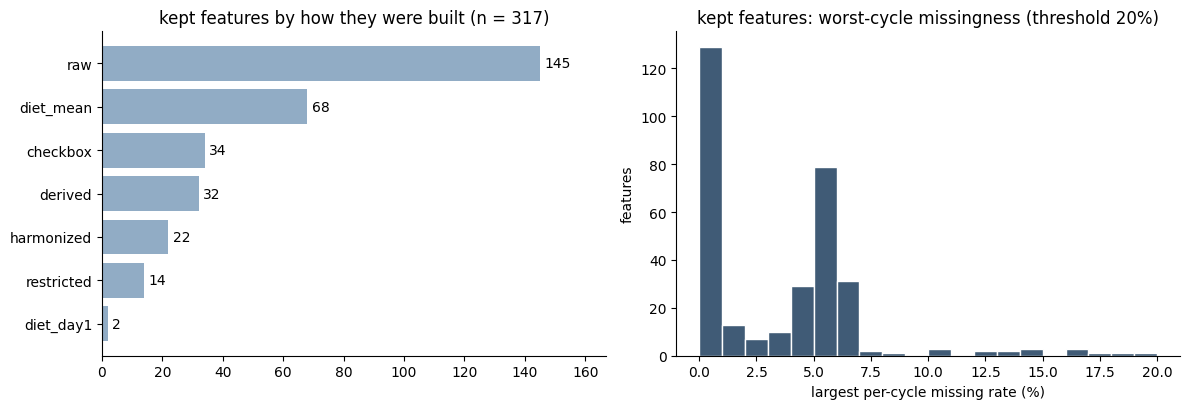

In [7]:
kept_dic = dic[dic.status == "kept"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
k = kept_dic.kind.value_counts().sort_values()
axes[0].barh(k.index, k.values, color="#91ACC5")
for i, v in enumerate(k.values):
    axes[0].text(v + k.max() * 0.01, i, str(v), va="center")
axes[0].set_xlim(0, k.max() * 1.15)
axes[0].set_title(f"kept features by how they were built (n = {len(kept_dic)})")
axes[1].hist(kept_dic.max_cycle_missing * 100, bins=np.arange(0, 21, 1), color="#405B76", edgecolor="white")
axes[1].set_xlabel("largest per-cycle missing rate (%)")
axes[1].set_ylabel("features")
axes[1].set_title("kept features: worst-cycle missingness (threshold 20%)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()